# Climate Comfort Index · Model comparison and promotion

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Selects one model, evaluates it once on the test split, and promotes it to production*

This is the **only notebook in the project that reads the test split**. It compares every exported CCI experiment on validation, selects one, scores it **once** on the test split, and copies it to `models/comfort_climate/production/` for the FastAPI service.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

| # | Step | What happens |
|:-:|:--|:--|
| 1 | Discover | Find every exported bundle under `models/comfort_climate/experiments/` |
| 2 | Feature contract | Keep only bundles fitted on the current feature set |
| 3 | Load data | Train, validation and test splits |
| 4 | Validation scores | Score every bundle and every baseline on validation |
| 5 | Select | Apply the selection rule, with baseline and noise checks |
| 6 | Test once | Score the winner on the test split |
| 7 | Promote | Copy the winner to `production/` with an audit record |
| 8 | Conclusions | What to carry into the report |

> **Why this order matters.** Nothing is refitted, so the models scored here are exactly the
> artefacts that would be deployed. Selection uses validation only. The test split is read in
> section 6, after the choice is final, so the test score is an honest estimate of performance on
> unseen dates. The validation score cannot play that role: every experiment tuned against it,
> and this notebook then picked the best of those tuned results.

---
## 0. Setup

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "comfort_climate"

task = wx.load_task(TASK)
print(f"{task.target_name} | selection metric: {task.metric} | targets: "
      f"{task.target_columns}")

Climate Comfort Index | selection metric: mae | targets: ['cci_t1', 'cci_t2', 'cci_t3']


---
## 1. Discover the exported experiments

Each experiment notebook saved a bundle in `models/comfort_climate/experiments/<experiment>/`. A bundle
listed with no models is a half-written experiment: rerun that notebook before trusting the
comparison, because a missing model is not a model that lost.

In [19]:
bundles = wx.discover_bundles(task)
wx.bundle_inventory(bundles)

,algorithm,models_found,horizons
experiment,,,
cci_dummy_mean,Dummy Regressor,3,"[1, 2, 3]"
cci_mlp,MLP Regressor,3,"[1, 2, 3]"
cci_polynomial_regression,Polynomial Ridge Regression,3,"[1, 2, 3]"
cci_random_forest,Random Forest Regressor,3,"[1, 2, 3]"
cci_xgboost,XGBoost Regressor,3,"[1, 2, 3]"


---
## 2. Feature-contract check

Every bundle recorded the feature columns it was trained on. A model trained on an older feature
set still loads and predicts, but its scores describe a different information set and cannot be
compared fairly. Such bundles are **excluded**; rerun their notebooks to include them.

In [20]:
contract = wx.check_feature_contract(bundles, task)
usable = contract["matches_current"] & contract["has_models"]
COMPARED = contract.index[usable].tolist()
EXCLUDED = contract.index[~usable].tolist()

if not COMPARED:
    raise RuntimeError("No bundle matches the current feature set. Rerun the experiment notebooks.")
print(f"Compared: {COMPARED}")
print(f"Excluded: {EXCLUDED or 'none'}")
contract

Compared: ['cci_dummy_mean', 'cci_mlp', 'cci_polynomial_regression', 'cci_random_forest', 'cci_xgboost']
Excluded: none


,n_features,matches_current,has_models
experiment,,,
cci_dummy_mean,105,True,True
cci_mlp,105,True,True
cci_polynomial_regression,105,True,True
cci_random_forest,105,True,True
cci_xgboost,105,True,True


---
## 3. Load the splits

The test split is loaded here to keep data access in one place, but it is **not used until
section 6**.

In [21]:
X, y = wx.load_splits(task, ("train", "val", "test"))

# Classification metrics are averaged over the classes seen in training.
LABELS = sorted(y["train"][task.target_columns[0]].unique()) if task.is_classification else None

pd.DataFrame({split: {"rows": len(X[split]), "start": X[split].index.min().date(),
                      "end": X[split].index.max().date()} for split in X}).T

,rows,start,end
train,2889,2016-01-31,2023-12-28
val,363,2024-01-01,2024-12-28
test,362,2025-01-01,2025-12-28


---
## 4. Score every experiment on validation

Each bundle is loaded and scored on the same validation data with the same metric functions as
the experiment notebooks. Nothing is refitted, so these numbers should reproduce the ones each
notebook reported; a mismatch means that bundle is stale. The baselines are scored alongside as
the bar every model must clear.

`pred_std` is included in the full table because it detects a model that has retreated toward the
average: two models with similar MAE but very different spread are not equivalent.

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DummyRegressor from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/A

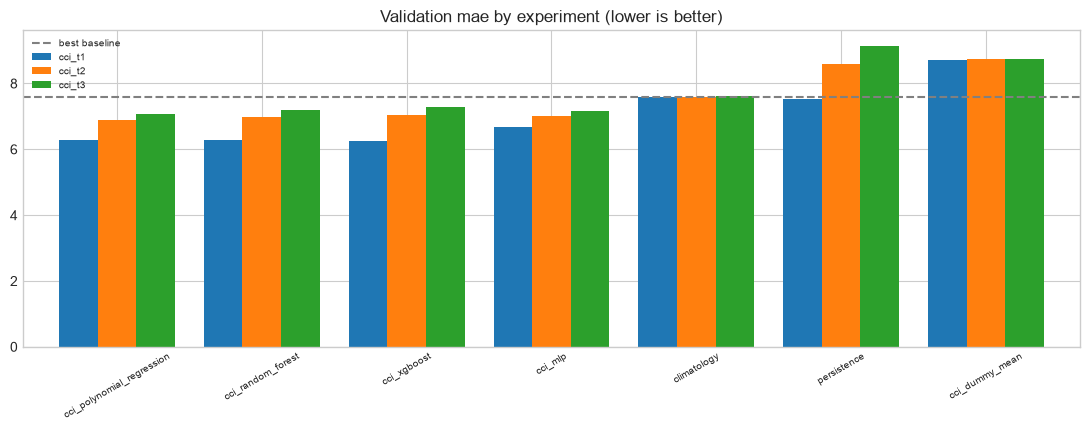

target,cci_t1,cci_t2,cci_t3,score,is_baseline
experiment,,,,,
cci_polynomial_regression,6.281,6.889,7.085,6.752,False
cci_random_forest,6.278,6.993,7.195,6.822,False
cci_xgboost,6.254,7.040,7.290,6.862,False
cci_mlp,6.673,7.016,7.148,6.946,False
climatology,7.588,7.600,7.610,7.599,True
persistence,7.531,8.591,9.152,8.425,True
cci_dummy_mean,8.725,8.737,8.750,8.737,False


In [22]:
models, columns, rows = {}, {}, []
for name in COMPARED:
    columns[name] = wx.bundle_feature_columns(bundles[name], task)
    models[name] = wx.load_bundle_models(bundles[name], task.horizons)
    rows += wx.score_models(task, name, models[name], columns[name], X, y, "val", LABELS)
rows += wx.score_baselines(task, X, y, "val", LABELS)

scores = pd.DataFrame(rows)
ranking = wx.rank_experiments(task, scores)

wx.plot_ranking(task, ranking, f"{task.name}-comparison-validation")
plt.show()
ranking

In [23]:
# Full validation metrics for the report.
scores.drop(columns=["split", "is_baseline"]).set_index(["experiment", "target"])

mae   rmse     r2  pred_std
experiment                target                              
cci_dummy_mean            cci_t1 8.725 11.100 -0.023     0.000
                          cci_t2 8.737 11.111 -0.023     0.000
                          cci_t3 8.750 11.116 -0.022     0.000
cci_mlp                   cci_t1 6.673  8.630  0.381     7.912
                          cci_t2 7.016  9.260  0.290     6.414
                          cci_t3 7.148  9.352  0.276     5.205
cci_polynomial_regression cci_t1 6.281  8.380  0.417     7.087
                          cci_t2 6.889  9.147  0.307     5.078
                          cci_t3 7.085  9.428  0.265     4.592
cci_random_forest         cci_t1 6.278  8.308  0.427     6.604
                          cci_t2 6.993  9.310  0.282     4.972
                          cci_t3 7.195  9.587  0.240     4.411
cci_xgboost               cci_t1 6.254  8.336  0.423     6.447
                          cci_t2 7.040  9.317  0.281     5.030
                          cci_t3 7.290  9.673  0.226     4.366
persistence               cci_t1 7.531  9.861  0.192    10.907
climatology               cci_t1 7.588 10.101  0.153     3.729
persistence               cci_t2 8.591 11.479 -0.092    10.907
climatology               cci_t2 7.600 10.106  0.154     3.727
persistence               cci_t3 9.152 11.959 -0.183    10.907
climatology               cci_t3 7.610 10.107  0.155     3.726

---
## 5. Rank and select

The selection rule is **lowest mean validation MAE across the three horizons**, fixed **before** looking at the results.

The mean over horizons is used because all three models ship together behind one endpoint. A
model that wins at *t*+1 but loses badly at *t*+3 would be the wrong choice: the longest horizon is
where users have the least information of their own.

Two checks are made rather than assumed:

- **Against the baselines** — the winner must beat the best baseline on every target.
- **Against noise** — if the margin over the runner-up is smaller than the typical seed spread
  recorded by the experiments, the ranking does not really separate the top two; the report should
  say so and choose on secondary grounds (cost, interpretability, artefact size).

In [24]:
selection = wx.select_best(task, ranking, bundles)
BEST = selection["best"]

print(f"Selected : {BEST} ({task.metric} = {selection['best_score']:.4f})")
print(f"Runner-up: {selection['runner_up']} (margin {selection['margin']:.4f})")
print(f"Typical seed spread: {selection['typical_seed_spread']:.4f}")
for message in selection["warnings"]:
    print(f"WARNING: {message}")

Selected : cci_polynomial_regression (mae = 6.7516)
Runner-up: cci_random_forest (margin 0.0704)
Typical seed spread: 0.0867


---
## 6. Single test evaluation

The test split is scored **once**, for the selected model and the baselines only. Nothing after
this point changes the selection.

Expect the test score to be somewhat worse than validation: that is the selection optimism being
paid back, not a failure. A small gap suggests a robust selection; a large one suggests the ranking
was fitted to 2024's particular weather and belongs in the limitations section.

> The selected model is **not** refitted on train + validation. Refitting would add a year of
> data, but the promoted artefact would then differ from the one its experiment notebook
> documented and evaluated. Keeping it unchanged keeps the chain from experiment to production
> auditable.

Selection optimism for cci_polynomial_regression (mae):


,validation,test,test_minus_validation
target,,,
cci_t1,6.281,6.782,0.502
cci_t2,6.889,7.666,0.777
cci_t3,7.085,7.851,0.766


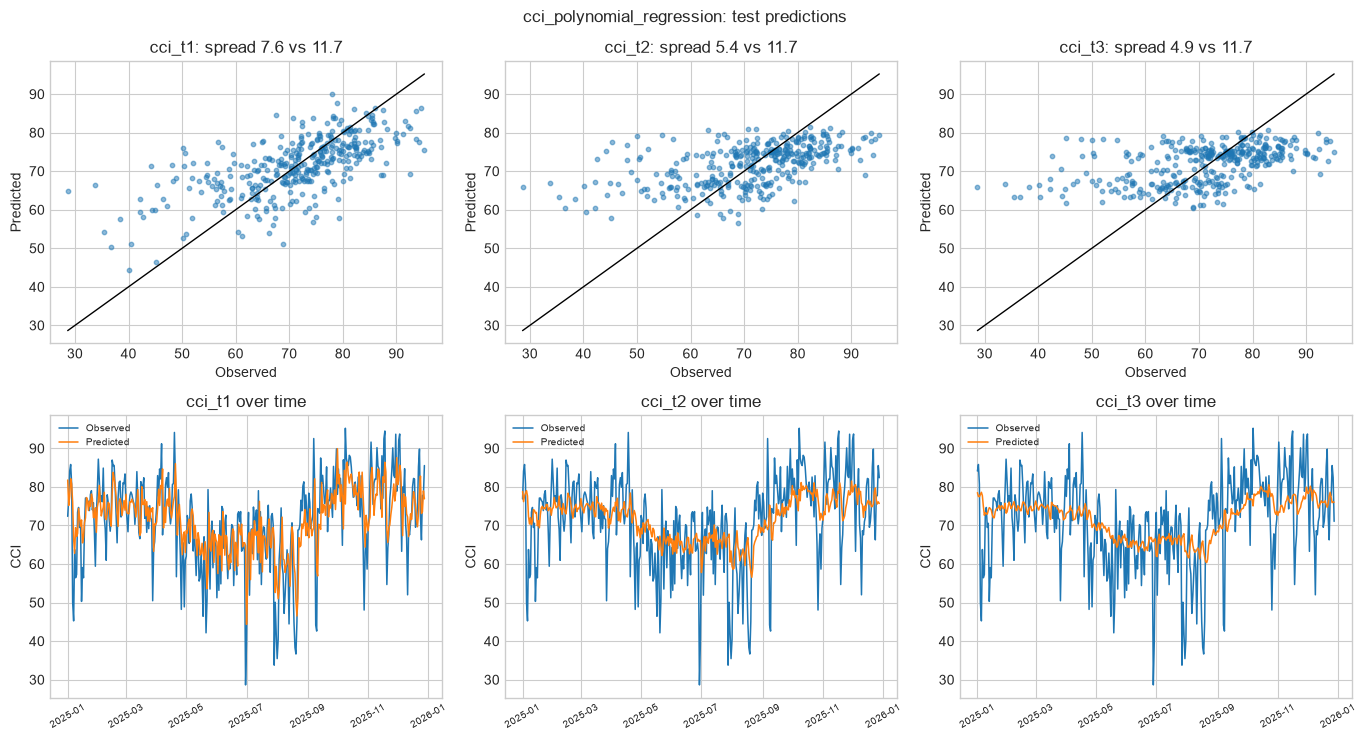

is_baseline    mae   rmse     r2  pred_std
target experiment                                                           
cci_t1 cci_polynomial_regression        False  6.782  8.949  0.418     7.557
cci_t2 cci_polynomial_regression        False  7.666 10.088  0.262     5.366
cci_t3 cci_polynomial_regression        False  7.851 10.373  0.219     4.854
cci_t1 persistence                       True  7.722 10.088  0.260    11.721
       climatology                       True  8.238 10.789  0.154     3.728
cci_t2 persistence                       True  9.582 12.601 -0.152    11.721
       climatology                       True  8.256 10.794  0.155     3.728
cci_t3 persistence                       True 10.070 13.384 -0.300    11.721
       climatology                       True  8.257 10.795  0.154     3.727

In [25]:
test_rows = (wx.score_models(task, BEST, models[BEST], columns[BEST], X, y, "test", LABELS)
             + wx.score_baselines(task, X, y, "test", LABELS))
test_scores = pd.DataFrame(test_rows).drop(columns=["split"]).set_index(["target", "experiment"])

optimism = pd.DataFrame({
    "validation": ranking.loc[BEST, task.target_columns].astype(float),
    "test": test_scores.xs(BEST, level="experiment")[task.metric],
})
optimism["test_minus_validation"] = optimism["test"] - optimism["validation"]
print(f"Selection optimism for {BEST} ({task.metric}):")
display(optimism)

wx.plot_test_predictions(task, models[BEST], columns[BEST], X, y,
                         f"{BEST}: test predictions", f"{task.name}-comparison-test")
plt.show()
test_scores

---
## 7. Promote to production

The selected bundle is **copied** (not moved) to `models/comfort_climate/production/`, together with
`promotion.json` recording what was chosen, on what evidence, when, and any warnings raised above.
The production folder is replaced rather than merged, so exactly one model is live per task.

> **The FastAPI service loads from `production/`, never from `experiments/`.**

In [26]:
record = wx.promotion_record(task, selection, ranking, test_scores, bundles[BEST],
                             COMPARED, EXCLUDED)
destination = wx.promote_bundle(task, bundles[BEST], record)

print(f"Promoted {BEST} -> {destination.relative_to(task.root)}")
sorted(path.name for path in destination.iterdir())

Promoted cci_polynomial_regression -> models/comfort_climate/production


['cci_polynomial_regression_h1.joblib',
 'cci_polynomial_regression_h2.joblib',
 'cci_polynomial_regression_h3.joblib',
 'manifest.json',
 'metadata.json',
 'promotion.json']

---
## 8. Conclusions

Points to carry into the report:

- **The selection, and how close it was.** Name the winner, the runner-up and the margin, and say
  whether the margin survives the seed-spread check. A close result reported as a clear win is the
  most common way a model comparison misleads.
- **Quote the test score, not the validation score.** The validation figure selected the model and
  cannot also measure it.
- **The size of the optimism.** The validation-to-test gap shows how much the selection fitted
  2024 specifically.
- **What beat the baselines, and where.** Improvement over the naive forecasts is more informative
  than any absolute number.
- **What is live.** `production/` holds exactly one bundle and `promotion.json` records why.

> Rerun this notebook whenever an experiment is rerun, so the promotion record never refers to a
> bundle that has since been overwritten.